SUPPORT VECTOR MACHINE

Task 1: Exploratory Data Analysis (EDA)     
1.	Load the dataset and perform fundamental data exploration.      
2.	Utilize histograms, box plots, or density plots to understand feature distributions.        
3.	Investigate feature correlations to discern relationships within the data.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df=pd.read_csv('Pharma_Industry.csv')

In [6]:
df.head()

,Drug Dosage (mg),Systolic Blood Pressure (mmHg),Heart Rate (BPM),Liver Toxicity Index (U/L),Blood Glucose Level (mg/dL),Drug Response
0,-0.128538,0.303280,-1.881849,0.258286,-0.792011,1
1,-1.846188,2.865142,-0.929511,2.866786,-0.719447,1
2,-1.252393,-1.541613,0.363632,-0.325370,0.191314,0
3,1.992515,-1.142779,-0.766657,0.975286,-0.823355,1
4,0.377100,0.538410,-0.029263,1.896015,-0.960130,1


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Drug Dosage (mg)                500 non-null    float64
 1   Systolic Blood Pressure (mmHg)  500 non-null    float64
 2   Heart Rate (BPM)                500 non-null    float64
 3   Liver Toxicity Index (U/L)      500 non-null    float64
 4   Blood Glucose Level (mg/dL)     500 non-null    float64
 5   Drug Response                   500 non-null    int64  
dtypes: float64(5), int64(1)
memory usage: 23.6 KB


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe()

,Drug Dosage (mg),Systolic Blood Pressure (mmHg),Heart Rate (BPM),Liver Toxicity Index (U/L),Blood Glucose Level (mg/dL),Drug Response
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.0000
mean,-0.037761,0.214957,0.062871,0.054398,-0.171863,0.5200
std,0.979891,1.247567,0.971978,0.986001,0.983765,0.5001
min,-3.019512,-3.773897,-2.940389,-3.401277,-3.110431,0.0000
25%,-0.642003,-0.565168,-0.648157,-0.586085,-0.797715,0.0000
50%,-0.019340,0.201532,0.027732,-0.065661,-0.108106,1.0000
75%,0.641151,0.951375,0.710774,0.633914,0.513555,1.0000
max,2.949094,4.111751,3.193108,3.373269,2.518023,1.0000


In [10]:
df.columns

Index(['Drug Dosage (mg)', 'Systolic Blood Pressure (mmHg)',
       'Heart Rate (BPM)', 'Liver Toxicity Index (U/L)',
       'Blood Glucose Level (mg/dL)', 'Drug Response'],
      dtype='str')

Task 2: Data Preprocessing      
1.	Encode categorical variables if necessary.      
2.	Split the dataset into training and testing sets.


In [11]:
target=df['Drug Response']
features=df.drop(columns=['Drug Response'])

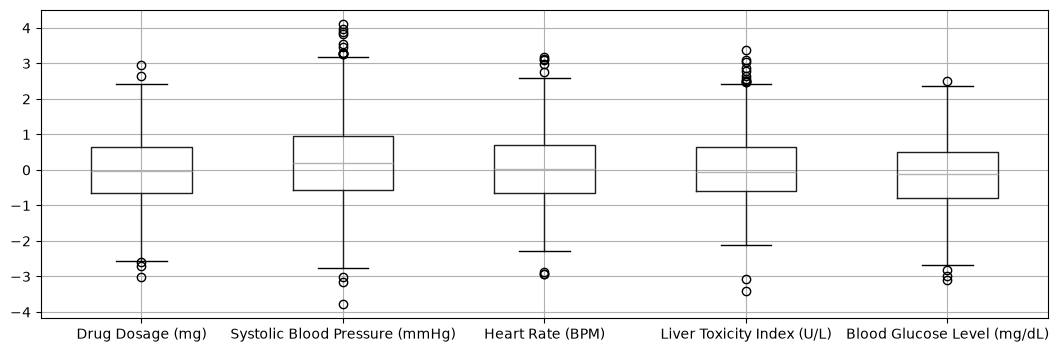

In [12]:
plt.figure(figsize=(13,4))
features.boxplot()
plt.show()

In [13]:
#### outlier capping
def outlier_capping(df,column):
    Q1= df[column].quantile(0.25)
    Q3= df[column].quantile(0.75)
    IQR= Q3-Q1
    lower_extreme= Q1-1.5*IQR
    upper_extreme= Q3+1.5*IQR
    df[column]= df[column].apply(lambda x: lower_extreme if x< lower_extreme else upper_extreme if x>upper_extreme else x)
for col in features.select_dtypes(include=['int','float']).columns:
    outlier_capping(features,col)

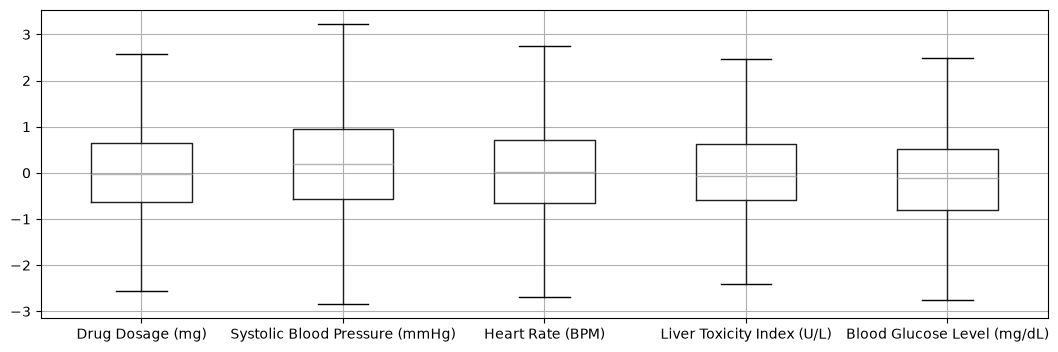

In [14]:
plt.figure(figsize=(13,4))
features.boxplot()
plt.show()

In [15]:
df2=features.join(target)

In [16]:
df2

,Drug Dosage (mg),Systolic Blood Pressure (mmHg),Heart Rate (BPM),Liver Toxicity Index (U/L),Blood Glucose Level (mg/dL),Drug Response
0,-0.128538,0.303280,-1.881849,0.258286,-0.792011,1
1,-1.846188,2.865142,-0.929511,2.463913,-0.719447,1
2,-1.252393,-1.541613,0.363632,-0.325370,0.191314,0
3,1.992515,-1.142779,-0.766657,0.975286,-0.823355,1
4,0.377100,0.538410,-0.029263,1.896015,-0.960130,1
...,...,...,...,...,...,...
495,-1.553759,0.506938,0.817890,-0.661245,-1.345393,0
496,0.551476,1.714321,0.340589,1.712558,-0.496315,1
497,-1.072743,-0.221137,0.239247,1.112924,-0.285838,1
498,1.661259,0.245759,-0.457096,0.633355,0.657413,0


In [17]:
cor=df2.corr()

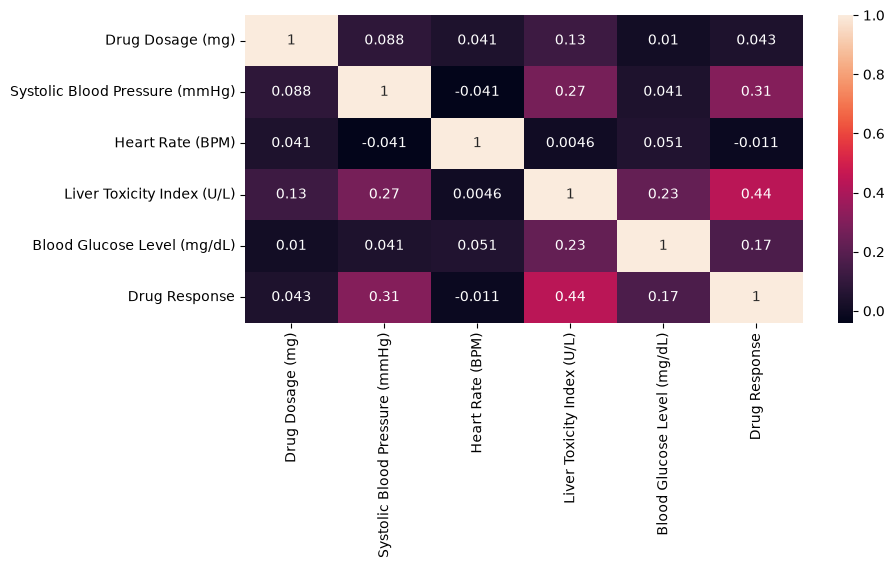

In [18]:
plt.figure(figsize=(9,4))
sns.heatmap(cor,annot=True)
plt.show()

In [19]:
from sklearn.model_selection import train_test_split

In [20]:
x_train,x_test,y_train,y_test=train_test_split(features,target,test_size=0.3,random_state=42)

In [21]:
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((350, 5), (150, 5), (350,), (150,))

In [22]:
from sklearn.preprocessing import StandardScaler

In [23]:
std_sca=StandardScaler()

In [24]:
x_train=std_sca.fit_transform(x_train)
x_test=std_sca.transform(x_test)

Task 3: Data Visualization      
1.	Employ scatter plots, pair plots, or relevant visualizations to comprehend feature distributions and relationships.     
2.	Visualize class distributions to gauge dataset balance or imbalance.


C:\Users\pprem\AppData\Local\Temp\ipykernel_27076\3573528925.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax=sns.countplot(x='Drug Response',data=df,palette='Set2')


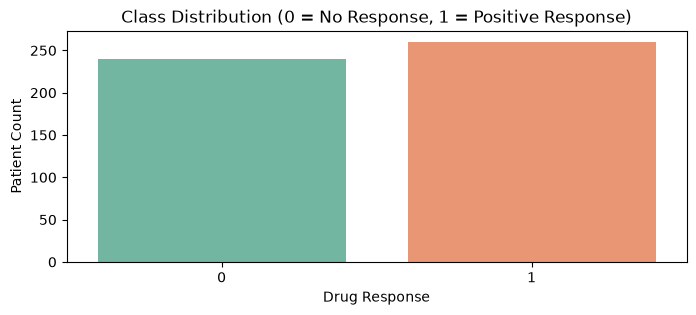

In [25]:
#Class Distribution
plt.figure(figsize=(8,3))
ax=sns.countplot(x='Drug Response',data=df,palette='Set2')
plt.title('Class Distribution (0 = No Response, 1 = Positive Response)')
plt.xlabel('Drug Response')
plt.ylabel('Patient Count')
plt.show()

<Figure size 700x400 with 0 Axes>

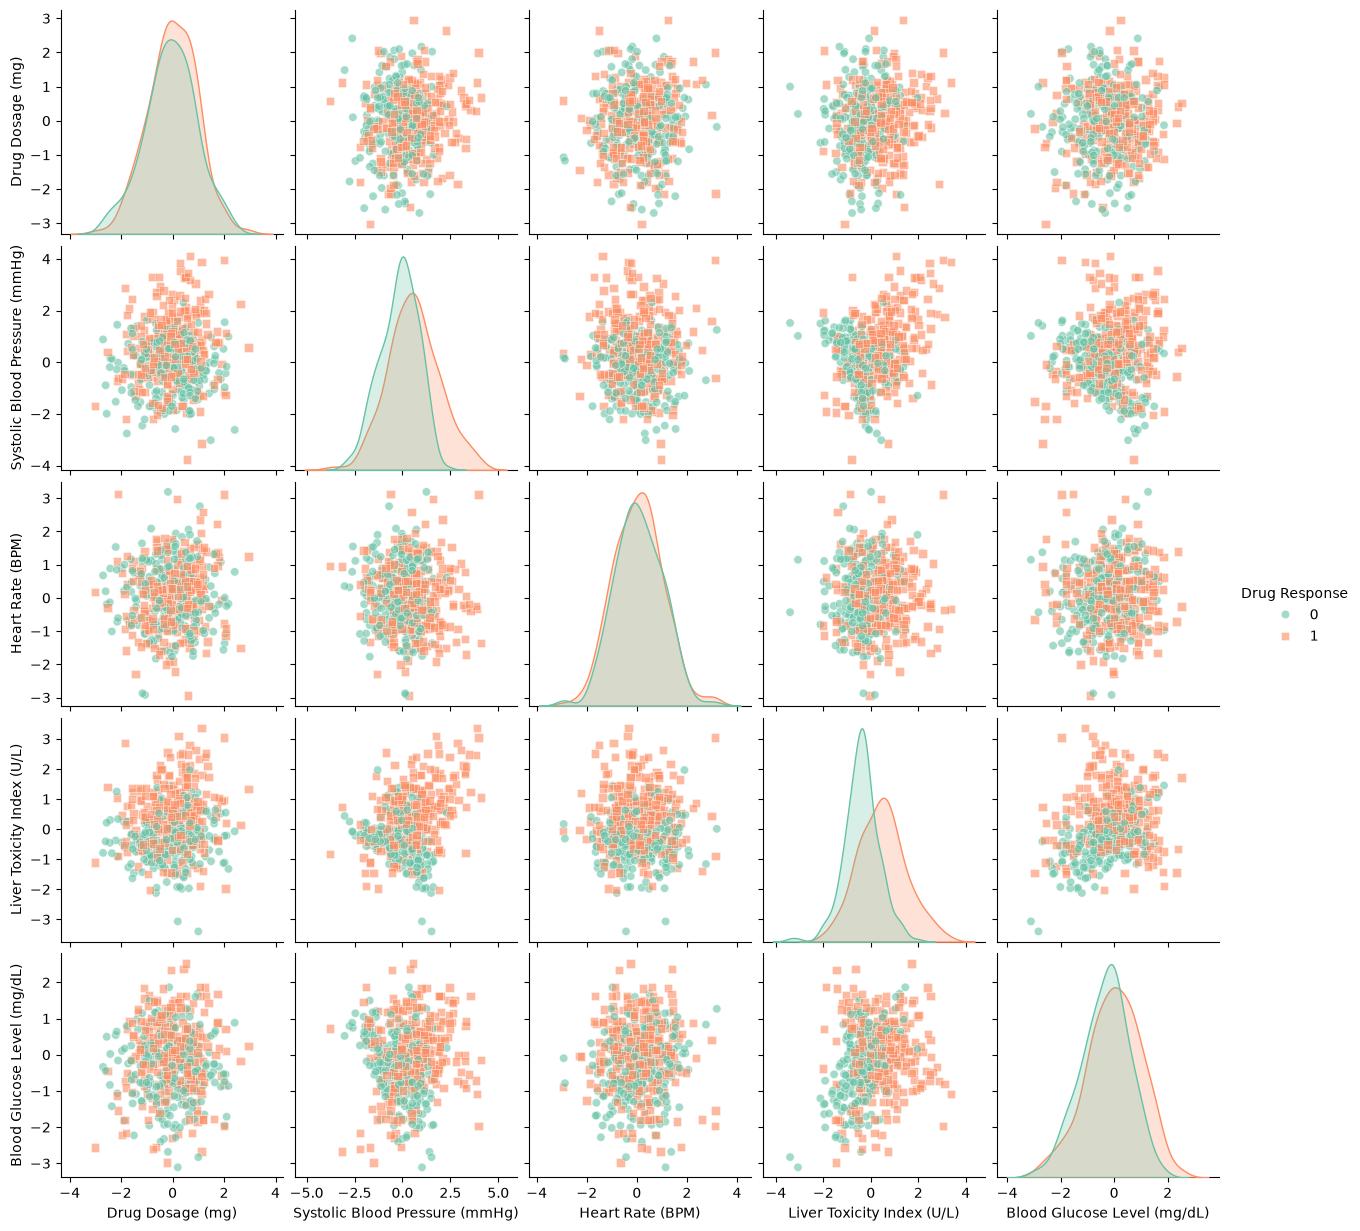

In [26]:
plt.figure(figsize=(7,4))
sns.pairplot(df,hue='Drug Response',palette='Set2',diag_kind='kde',markers=["o", "s"],plot_kws={'alpha': 0.6})
plt.show()

Task 4: SVM Implementation      
1.	Implement a basic SVM classifier using Python libraries like scikit-learn.      
2.	Train the SVM model on the training data.       
3.	Evaluate model performance on the testing data using appropriate metrics (e.g., accuracy, precision, recall, F1-score).


In [38]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix,ConfusionMatrixDisplay

In [28]:
svm_model=SVC()

In [29]:
svm_model.fit(x_train,y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [30]:
y_pred=svm_model.predict(x_test)

In [32]:
acc=accuracy_score(y_test,y_pred)
acc

0.78

In [35]:
report=classification_report(y_test,y_pred)

In [37]:
print(report)

              precision    recall  f1-score   support

           0       0.73      0.83      0.78        69
           1       0.83      0.74      0.78        81

    accuracy                           0.78       150
   macro avg       0.78      0.78      0.78       150
weighted avg       0.79      0.78      0.78       150



Task 5: Visualization of SVM Results        
1.	Visualize classification results on the testing data.


In [39]:
cm=confusion_matrix(y_test,y_pred)
cm

array([[57, 12],
       [21, 60]])

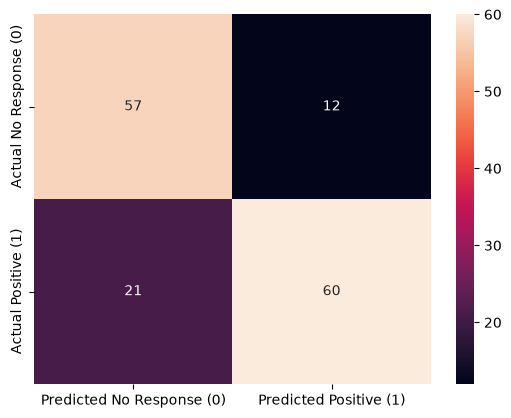

In [45]:
sns.heatmap(cm,annot=True,xticklabels=['Predicted No Response (0)','Predicted Positive (1)'],
            yticklabels=['Actual No Response (0)','Actual Positive (1)'])
plt.show()

Task 6: Parameter Tuning and Optimization       
1.	Experiment with different SVM hyperparameters (e.g., kernel type, regularization parameter) to optimize performance.


In [46]:
from sklearn.model_selection import GridSearchCV

In [47]:
params={
    'C':[0.1,1,10,100],
    'kernel':['linear','poly','rbf'],
    'gamma':['scale','auto',0.1,1]
}

In [48]:
grid_search=GridSearchCV(SVC(),param_grid=params,cv=5,scoring='accuracy',n_jobs=-1)
grid_search.fit(x_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 1, ...], 'gamma': ['scale', 'auto', ...], 'kernel': ['linear', 'poly', ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of inf

In [49]:
grid_search.best_params_,grid_search.best_estimator_

({'C': 0.1, 'gamma': 0.1, 'kernel': 'rbf'}, SVC(C=0.1, gamma=0.1))

In [50]:
best_model=grid_search.best_estimator_
y_pred=best_model.predict(x_test)

In [52]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.64      0.87      0.74        69
           1       0.84      0.58      0.69        81

    accuracy                           0.71       150
   macro avg       0.74      0.72      0.71       150
weighted avg       0.75      0.71      0.71       150



Task 7: Comparison and Analysis     
1.	Compare SVM performance with various kernels (e.g., linear, polynomial, radial basis function).     
2.	Analyze SVM strengths and weaknesses for the dataset based on EDA and visualization results.        
3.	Discuss practical implications of SVM in real-world classification tasks.


In [54]:
#linear
model=SVC(kernel='linear', random_state=42)
model.fit(x_train, y_train)
y_pred=model.predict(x_test)
accuracy_score(y_test,y_pred)

0.7066666666666667

In [55]:
#polynomial
model=SVC(kernel='poly', random_state=42)
model.fit(x_train, y_train)
y_pred=model.predict(x_test)
accuracy_score(y_test,y_pred)

0.7133333333333334

In [56]:
#radial basis function
model=SVC(kernel='rbf', random_state=42)
model.fit(x_train, y_train)
y_pred=model.predict(x_test)
accuracy_score(y_test,y_pred)

0.78

In [57]:
#sigmoid
model=SVC(kernel='sigmoid', random_state=42)
model.fit(x_train, y_train)
y_pred=model.predict(x_test)
accuracy_score(y_test,y_pred)

0.7266666666666667

In [58]:
print("""  

The RBF SVM effectively handles complex, overlapping patient biomarkers where simple linear models could not perform well, accurately 
predicting  drug responses by leveraging key features like the liver toxicity index. In contrast, the Linear kernel is fundamentally weak 
for this dataset because the biological data lacks clear linear boundaries. Despite its strong overall precision, the model's primary flaw 
is a higher rate of false negatives, meaning it occasionally misses patients who would actually improve from the treatment.

""")

  

The RBF SVM effectively handles complex, overlapping patient biomarkers where simple linear models could not perform well, accurately 
predicting  drug responses by leveraging key features like the liver toxicity index. In contrast, the Linear kernel is fundamentally weak 
for this dataset because the biological data lacks clear linear boundaries. Despite its strong overall precision, the model's primary flaw 
is a higher rate of false negatives, meaning it occasionally misses patients who would actually improve from the treatment.




In [59]:
print("""

practical implications of SVM in real-world classification tasks are face detection,bioinformatics,handwriting recognition.

""")



practical implications of SVM in real-world classification tasks are face detection,bioinformatics,handwriting recognition.


